In [1]:
import os, sys
import numpy as np
import pickle
import uproot
import glob
import pandas as pd
from tqdm import tqdm
import json
import ROOT as rt
import fnmatch

## user define
sys.path.append('.')
sys.path.append('./Utils')
from Plotter import HistStack

from beeps import *

Welcome to JupyROOT 6.26/08


# Set config

In [2]:
# ERA="ee17"
# ERA="ee16pre"
# # ERA="mm18"
# ERA="em18"
# # DATE = '20230129_17_eleffmva'
# DATE = '20230301_18'
# # DATE = '20230130_18_dyhighworctight'
# # INPUTDIR = "/eos/user/h/hkwon/Run2/20230130_18_dyhighworctight/mm/"
# INPUTDIR = "/eos/user/h/hkwon/Run2/20230301_18/em/"
import sys
ERA = sys.argv[1]
DATE = sys.argv[2]
INPUTDIR = sys.argv[3]

DUMP_PKL = False
DRAW_SR = True
RUN_SIDEBAND_MET = False
RUN_SIDEBAND_MASS = False
RUN_SIDEBAND_PT = False
DUMP_SIDEBAND_MET_PKL = False
DUMP_SIDEBAND_MASS_PKL = False
DUMP_SIDEBAND_PT_PKL = False
RUN_BTAG = True
EXPORT_VARIABLE = False

# # for dev
# ERA = "em18"
# DATE = "20230523deepCSV_18"
# INPUTDIR = "/eos/user/h/hkwon/Run2/"+DATE+"/em/"


# Get input

In [3]:
lumi_all={
    "ee16pre":19520,
    "ee16post":16810,
    "ee17":41480,
    "ee18":59830,
    "mm16pre":19520,
    "mm16post":16810,
    "mm17":41480,
    "mm18":59830,    
#     "mm18":14000,    
    "em16pre":19520,
    "em16post":16810,
    "em17":41480,
    "em18":59830     
}

data_evts = {
    "ee16pre":652566543,
    "ee16post":287977113,
    "ee17":460041183,
    "ee18":1326465857,
    "mm16pre":458655573,
    "mm16post":327037312,
    "mm17":739073837,
#     "mm18":944842550,  #949352777 
    "mm18":949352777,  #949352777 
    "em16pre":1111222116,
    "em16post":615014425,
    "em17":1199115020,
#     "em18":2271308407   #2281001366  
    "em18":2281001366   #2281001366  
}

lumi=lumi_all[ERA]
print(ERA, lumi)

channel = ERA.replace("16pre", "")
channel = channel.replace("16post", "")
channel = channel.replace("17", "")
channel = channel.replace("18", "")

def get_df(root_file_name, unneccesary_columns):
    f = uproot.open(root_file_name)
    df = uproot.open(root_file_name)["Events_"+channel].arrays(library="pd")
    df_met_u = uproot.open(root_file_name)["Events_"+channel+"_met_u"].arrays(library="pd")
    df_met_d = uproot.open(root_file_name)["Events_"+channel+"_met_d"].arrays(library="pd")    
    df_met_ue_u = uproot.open(root_file_name)["Events_"+channel+"_met_ue_u"].arrays(library="pd")
    df_met_ue_d = uproot.open(root_file_name)["Events_"+channel+"_met_ue_d"].arrays(library="pd") 
    #     df_scale_u = uproot.open(root_file_name)["Events_"+channel+"_scale_u"].arrays(library="pd")
#     df_scale_d = uproot.open(root_file_name)["Events_"+channel+"_scale_d"].arrays(library="pd")
    info = uproot.open(root_file_name)["Info_"+channel].arrays(library="pd")
#     return sum(info["sumweight"]), df.drop(unneccesary_columns, axis=1), df_met_u.drop(unneccesary_columns, axis=1), df_met_d.drop(unneccesary_columns, axis=1), df_scale_u.drop(unneccesary_columns, axis=1), df_scale_d.drop(unneccesary_columns, axis=1)
    return sum(info["sumweight"]), df.drop(unneccesary_columns, axis=1), df_met_u.drop(unneccesary_columns, axis=1), df_met_d.drop(unneccesary_columns, axis=1), df_met_ue_u.drop(unneccesary_columns, axis=1), df_met_ue_d.drop(unneccesary_columns, axis=1)

unneccesary_columns = []
dic_input = {
    "ee16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/ee/",
    "mm16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/mm/",
    "em16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/em/",
    "ee16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/ee/",
    "mm16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/mm/",
    "em16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/em/",
    "ee17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/ee/",
    "mm17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/mm/",
    "em17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/em/",
    "ee18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/ee/",
    "mm18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/mm/",    
    "em18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/em/"        
#     "em18": "/eos/user/h/hkwon/Run2/20221120_18/em/"        
}
# input_dir = dic_input[ERA]
input_dir = INPUTDIR
f = []
for (dirpath, dirnames, filenames) in os.walk(input_dir):
    f.extend(filenames)
    break

dic_tup={}
for file in tqdm(f):
    # file naming: flatNtuple_Preselect_WZ1.root, flatNtuple_Preselect_Zp-3700_CH-1345.root
    if not "flatNtuple" in file:
        continue
#     if channel=="mm" and (fnmatch.fnmatch(file, '*E*Run*') or fnmatch.fnmatch(file, '*M*RunB*') or fnmatch.fnmatch(file, '*M*RunC*') or fnmatch.fnmatch(file, '*M*RunD*')): #temp
    if channel=="mm" and fnmatch.fnmatch(file, '*E*Run*'): #temp
        continue
    if channel=="ee" and fnmatch.fnmatch(file, '*M*Run*'):
        continue
#     if channel=="em" and fnmatch.fnmatch(file, '*E*Run*'):
#         continue  
    if "TT" in file and not "hadd" in file:
        continue
    if "DY" in file and not "hadd" in file:
        continue  
    if "TW" in file and not "hadd" in file:
        continue         
    if "WW" in file and not "hadd" in file:
        continue  
    if "WZ" in file and not "hadd" in file:
        continue      
    if "ZZ" in file and not "hadd" in file:
        continue  
        
    if "Zp" in file:
        sample=file.split('_')[2]+"_"+file.split('_')[3]
    else:
        sample=file.split('_')[2]
    sample=sample.rstrip('.root')
    try:
        print(sample)
        dic_tup[sample]=get_df(input_dir+file, unneccesary_columns)   
    except:
        print(sample)
        beep()        
        if "Run" in sample: # check file corrupt
            raise    
# dic_tup

em18 59830


  0%|          | 0/301 [00:00<?, ?it/s]

DY


  9%|▉         | 28/301 [00:01<00:16, 16.12it/s]

E18RunA0
E18RunA1


...

 99%|█████████▉| 299/301 [05:01<00:04,  2.36s/it]

antitop


100%|█████████▉| 300/301 [05:03<00:02,  2.06s/it]

top


100%|██████████| 301/301 [05:04<00:00,  1.01s/it]


In [4]:
beep_ok()

In [5]:
# for key in dic_tup:
#     print(key)

In [6]:
# get x-sec
dic_xsec={}
with open('config/CrossSection.json') as json_file:
    data = json.load(json_file)
    dic_xsec=data
print(dic_xsec)

{'Data': 1, 'DY': 6077.22, 'DY500To700': 0.2558, 'DY700To800': 0.04023, 'DY800To1000': 0.03406, 'DY1000To1500': 0.01828, 'DY1500To2000': 0.002367, 'DY2000To3000': 0.0005409, 'TT': 88.29, 'TTUp': 88.29, 'TTDown': 88.29, 'TThdampUp': 88.29, 'TThdampDown': 88.29, 'TTSemi': 365.34, 'TTZ': 0.2432, 'top': 34.91, 'antitop': 34.91, 'WW': 10.48, 'WZ': 5.052, 'ZZ': 0.6008, 'Zp-1700_CH-345': 0.03523, 'Zp-1700_CH-595': 0.03523, 'Zp-1700_CH-845': 0.03523, 'Zp-2100_CH-345': 0.01198, 'Zp-2100_CH-595': 0.01198, 'Zp-2100_CH-845': 0.01198, 'Zp-2500_CH-345': 0.004396, 'Zp-2500_CH-595': 0.004396, 'Zp-2500_CH-845': 0.004396, 'Zp-2500_CH-1095': 0.004396, 'Zp-2900_CH-345': 0.001768, 'Zp-2900_CH-595': 0.001768, 'Zp-2900_CH-845': 0.001768, 'Zp-2900_CH-1095': 0.001768, 'Zp-2900_CH-1345': 0.001768, 'Zp-3300_CH-345': 0.000729, 'Zp-3300_CH-595': 0.000729, 'Zp-3300_CH-845': 0.000729, 'Zp-3300_CH-1095': 0.000729, 'Zp-3300_CH-1345': 0.000729, 'Zp-3300_CH-1595': 0.000729, 'Zp-3700_CH-345': 0.00031, 'Zp-3700_CH-595': 0

In [7]:
Data_concat, TT_concat, TTSemi_concat, TTZ_concat, DY_concat, top_concat, antitop_concat, WW_concat, WZ_concat, ZZ_concat = ([] for i in range(10))
Data_concat_met_u, TT_concat_met_u, TTSemi_concat_met_u, TTZ_concat_met_u, DY_concat_met_u, top_concat_met_u, antitop_concat_met_u, WW_concat_met_u, WZ_concat_met_u, ZZ_concat_met_u = ([] for i in range(10))
Data_concat_met_d, TT_concat_met_d, TTSemi_concat_met_d, TTZ_concat_met_d, DY_concat_met_d, top_concat_met_d, antitop_concat_met_d, WW_concat_met_d, WZ_concat_met_d, ZZ_concat_met_d = ([] for i in range(10))
Data_concat_scale_u, TT_concat_scale_u, TTSemi_concat_scale_u, TTZ_concat_scale_u, DY_concat_scale_u, top_concat_scale_u, antitop_concat_scale_u, WW_concat_scale_u, WZ_concat_scale_u, ZZ_concat_scale_u = ([] for i in range(10))
Data_concat_scale_d, TT_concat_scale_d, TTSemi_concat_scale_d, TTZ_concat_scale_d, DY_concat_scale_d, top_concat_scale_d, antitop_concat_scale_d, WW_concat_scale_d, WZ_concat_scale_d, ZZ_concat_scale_d = ([] for i in range(10))
TTUp_concat, TTDown_concat, TThdampUp_concat, TThdampDown_concat = ([] for i in range(4)) 
TTUp_concat_met_u, TTDown_concat_met_u, TThdampUp_concat_met_u, TThdampDown_concat_met_u = ([] for i in range(4)) 
TTUp_concat_met_d, TTDown_concat_met_d, TThdampUp_concat_met_d, TThdampDown_concat_met_d = ([] for i in range(4)) 
Data_concat_met_ue_u, Data_concat_met_ue_d = ([] for i in range(2))  

Data_nevts, TT_nevts, TTSemi_nevts, TTZ_nevts, DY_nevts, top_nevts, antitop_nevts, WW_nevts, WZ_nevts, ZZ_nevts = ([] for i in range(10))
TTUp_nevts, TTDown_nevts, TThdampUp_nevts, TThdampDown_nevts = ([] for i in range(4))

merged_dic_df={}
for key in dic_tup:
#     if fnmatch.fnmatch(key, 'DY?') or fnmatch.fnmatch(key, 'DY1?'):
#         print(key)
# #         print(dic_tup[key][0])
#         DY_concat.append(dic_tup[key][1])
#         DY_concat_met_u.append(dic_tup[key][2])
#         DY_concat_met_d.append(dic_tup[key][3])        
# #         DY_concat_scale_u.append(dic_tup[key][4])
# #         DY_concat_scale_d.append(dic_tup[key][5])
#         DY_nevts.append(dic_tup[key][0])        
#     if fnmatch.fnmatch(key, 'TT?') or fnmatch.fnmatch(key, 'TT1?'):
# #         print("TT", key)
# #         print(dic_tup[key][0])
#         TT_concat.append(dic_tup[key][1])
#         TT_concat_met_u.append(dic_tup[key][2])
#         TT_concat_met_d.append(dic_tup[key][3])
# #         TT_concat_scale_u.append(dic_tup[key][4])
# #         TT_concat_scale_d.append(dic_tup[key][5])
#         TT_nevts.append(dic_tup[key][0])
#     if fnmatch.fnmatch(key, 'TThdampUp?') or fnmatch.fnmatch(key, 'TThdampUp1?'):
# #         print(key)
# #         print(dic_tup[key][0])
#         TThdampUp_concat.append(dic_tup[key][1])
#         TThdampUp_concat_met_u.append(dic_tup[key][2])
#         TThdampUp_concat_met_d.append(dic_tup[key][3])
#         TThdampUp_nevts.append(dic_tup[key][0])
#     if fnmatch.fnmatch(key, 'TThdampDown?') or fnmatch.fnmatch(key, 'TThdampDown1?'):
# #         print(key)
# #         print(dic_tup[key][0])
#         TThdampDown_concat.append(dic_tup[key][1])
#         TThdampDown_concat_met_u.append(dic_tup[key][2])
#         TThdampDown_concat_met_d.append(dic_tup[key][3])
#         TThdampDown_nevts.append(dic_tup[key][0])
#     if fnmatch.fnmatch(key, 'TTUp?') or fnmatch.fnmatch(key, 'TTUp1?'):
# #         print(key)
# #         print(dic_tup[key][0])
#         TTUp_concat.append(dic_tup[key][1])
#         TTUp_concat_met_u.append(dic_tup[key][2])
#         TTUp_concat_met_d.append(dic_tup[key][3])
#         TTUp_nevts.append(dic_tup[key][0])
#     if fnmatch.fnmatch(key, 'TTDown?') or fnmatch.fnmatch(key, 'TTDown1?'):
# #         print(key)
# #         print(dic_tup[key][0])
#         TTDown_concat.append(dic_tup[key][1])
#         TTDown_concat_met_u.append(dic_tup[key][2])
#         TTDown_concat_met_d.append(dic_tup[key][3])
#         TTDown_nevts.append(dic_tup[key][0])
#     if fnmatch.fnmatch(key, 'TTSemi*'):
# #         print(key)
# #         print(dic_tup[key][0])
#         TTSemi_concat.append(dic_tup[key][1])
#         TTSemi_concat_met_u.append(dic_tup[key][2])
#         TTSemi_concat_met_d.append(dic_tup[key][3])
# #         TTSemi_concat_scale_u.append(dic_tup[key][4])
# #         TTSemi_concat_scale_d.append(dic_tup[key][5])
#         TTSemi_nevts.append(dic_tup[key][0])
#     if fnmatch.fnmatch(key, 'TTZ*'):
# #         print(key)
# #         print(dic_tup[key][0])
#         TTZ_concat.append(dic_tup[key][1])
#         TTZ_concat_met_u.append(dic_tup[key][2])
#         TTZ_concat_met_d.append(dic_tup[key][3])
# #         TTZ_concat_scale_u.append(dic_tup[key][4])
# #         TTZ_concat_scale_d.append(dic_tup[key][5])
#         TTZ_nevts.append(dic_tup[key][0])
#     if fnmatch.fnmatch(key, 'TW?'):
# #         print(key)
# #         print(dic_tup[key][0])
#         top_concat.append(dic_tup[key][1])
#         top_concat_met_u.append(dic_tup[key][2])
#         top_concat_met_d.append(dic_tup[key][3])
# #         top_concat_scale_u.append(dic_tup[key][4])
# #         top_concat_scale_d.append(dic_tup[key][5])
#         top_nevts.append(dic_tup[key][0])        
#     elif fnmatch.fnmatch(key, 'TWa?'):
# #         print(key)
# #         print(dic_tup[key][0])
#         antitop_concat.append(dic_tup[key][1])
#         antitop_concat_met_u.append(dic_tup[key][2])
#         antitop_concat_met_d.append(dic_tup[key][3])
# #         antitop_concat_scale_u.append(dic_tup[key][4])
# #         antitop_concat_scale_d.append(dic_tup[key][5])
#         antitop_nevts.append(dic_tup[key][0]) 
#     if fnmatch.fnmatch(key, 'WW*'):
#         WW_concat.append(dic_tup[key][1])
#         WW_concat_met_u.append(dic_tup[key][2])
#         WW_concat_met_d.append(dic_tup[key][3])
# #         WW_concat_scale_u.append(dic_tup[key][4])
# #         WW_concat_scale_d.append(dic_tup[key][5])
#         WW_nevts.append(dic_tup[key][0])        
#     if fnmatch.fnmatch(key, 'WZ*'):
#         WZ_concat.append(dic_tup[key][1])
#         WZ_concat_met_u.append(dic_tup[key][2])
#         WZ_concat_met_d.append(dic_tup[key][3])
# #         WZ_concat_scale_u.append(dic_tup[key][4])
# #         WZ_concat_scale_d.append(dic_tup[key][5])
#         WZ_nevts.append(dic_tup[key][0])
#     elif fnmatch.fnmatch(key, 'ZZ*'):
#         ZZ_concat.append(dic_tup[key][1])
#         ZZ_concat_met_u.append(dic_tup[key][2])
#         ZZ_concat_met_d.append(dic_tup[key][3])
# #         ZZ_concat_scale_u.append(dic_tup[key][4])
# #         ZZ_concat_scale_d.append(dic_tup[key][5])
#         ZZ_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, '*Run*'):
        Data_concat.append(dic_tup[key][1])
        Data_concat_met_u.append(dic_tup[key][2])
        Data_concat_met_d.append(dic_tup[key][3])
        Data_concat_met_ue_u.append(dic_tup[key][4])
        Data_concat_met_ue_d.append(dic_tup[key][5])
#         Data_concat_scale_u.append(dic_tup[key][4])
#         Data_concat_scale_d.append(dic_tup[key][5])
        Data_nevts.append(dic_tup[key][0]) 
#     if fnmatch.fnmatch(key, 'Zp*'): 
#         merged_dic_df[key]=dic_tup[key]
#     if fnmatch.fnmatch(key, 'DY*To*'): 
#         merged_dic_df[key]=dic_tup[key]
# #         print("high", key)
    else: 
        merged_dic_df[key]=dic_tup[key]

In [8]:
dic_tup

{'DY': (128601645,
       PuppiMET_pre    mass_pre  pt_lead_pre  pt_trail_pre       U_pre  \
  0      102.034004  107.448845    87.177452     27.185463  198.166885   
  1      174.340698   89.516640    84.550400     33.866753  251.864120   
  2      106.901901   60.246861   125.112076     47.511974  270.707153   
  3      145.829468   64.550049   180.051773     46.960869  363.895935   
  4      147.880768  126.458778   101.694443     26.181213  270.930847   
  ..            ...         ...          ...           ...         ...   
  137    114.963486  166.078430    98.640556     35.958748   92.031174   
  138    166.507675   60.742416   134.362762     46.041100  338.750458   
  139    274.121124  102.011627    96.959297     45.212883  415.396942   
  140    134.599731   61.501831   113.790123     98.734528  340.525970   
  141    164.176285  138.746490   144.950348     28.803080   71.886375   
  
          JZB_pre  dPhill_pre  dPhilMET_pre      MT_pre   MT2_pre  ...  \
  0    101.63529

In [9]:
# # free memory 
# dic_tup.clear()

In [10]:
totalinput = """
######################################################
####   Total input number of events (sumweight)   ####
######################################################
"""

print(totalinput)
# if TT_concat:
# #     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d)
#     tmp = "TT: "+str(sum(TT_nevts))
#     print(tmp)
#     totalinput+=tmp+"\n"
# if TThdampUp_concat:
# #     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
#     merged_dic_df['TThdampUp']=sum(TThdampUp_nevts), pd.concat(TThdampUp_concat), pd.concat(TThdampUp_concat_met_u), pd.concat(TThdampUp_concat_met_d)
#     tmp = "TThdampUp: "+str(sum(TThdampUp_nevts))
#     print(tmp)
#     totalinput+=tmp+"\n"
# if TThdampDown_concat:
# #     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
#     merged_dic_df['TThdampDown']=sum(TThdampDown_nevts), pd.concat(TThdampDown_concat), pd.concat(TThdampDown_concat_met_u), pd.concat(TThdampDown_concat_met_d)
#     tmp = "TThdampDown: "+str(sum(TThdampDown_nevts))
#     print(tmp)
#     totalinput+=tmp+"\n"    
# if TTUp_concat:
# #     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
#     merged_dic_df['TTUp']=sum(TTUp_nevts), pd.concat(TTUp_concat), pd.concat(TTUp_concat_met_u), pd.concat(TTUp_concat_met_d)
#     tmp = "TTUp: "+str(sum(TTUp_nevts))
#     print(tmp)
#     totalinput+=tmp+"\n"
# if TTDown_concat:
# #     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
#     merged_dic_df['TTDown']=sum(TTDown_nevts), pd.concat(TTDown_concat), pd.concat(TTDown_concat_met_u), pd.concat(TTDown_concat_met_d)
#     tmp = "TTDown: "+str(sum(TTDown_nevts))
#     print(tmp)
#     totalinput+=tmp+"\n" 
# if TTSemi_concat:
# #     merged_dic_df['TTSemi']=sum(TTSemi_nevts), pd.concat(TTSemi_concat), pd.concat(TTSemi_concat_met_u), pd.concat(TTSemi_concat_met_d), pd.concat(TTSemi_concat_scale_u), pd.concat(TTSemi_concat_scale_d)
#     merged_dic_df['TTSemi']=sum(TTSemi_nevts), pd.concat(TTSemi_concat), pd.concat(TTSemi_concat_met_u), pd.concat(TTSemi_concat_met_d)
#     tmp = "TTSemi: "+str(sum(TTSemi_nevts))
#     print(tmp)
#     totalinput+=tmp+"\n"    
# if TTZ_concat:
# #     merged_dic_df['TTZ']=sum(TTZ_nevts), pd.concat(TTZ_concat), pd.concat(TTZ_concat_met_u), pd.concat(TTZ_concat_met_d), pd.concat(TTZ_concat_scale_u), pd.concat(TTZ_concat_scale_d)
#     merged_dic_df['TTZ']=sum(TTZ_nevts), pd.concat(TTZ_concat), pd.concat(TTZ_concat_met_u), pd.concat(TTZ_concat_met_d)
#     tmp = "TTZ: "+str(sum(TTZ_nevts))
#     print(tmp)
#     totalinput+=tmp+"\n"
# if DY_concat:
# #     merged_dic_df['DY']=sum(DY_nevts), pd.concat(DY_concat), pd.concat(DY_concat_met_u), pd.concat(DY_concat_met_d), pd.concat(DY_concat_scale_u), pd.concat(DY_concat_scale_d)
#     merged_dic_df['DY']=sum(DY_nevts), pd.concat(DY_concat), pd.concat(DY_concat_met_u), pd.concat(DY_concat_met_d)
#     tmp = "DY: "+str(sum(DY_nevts))
#     print(tmp)
#     totalinput+=tmp+"\n"    
# if top_concat:
#     df=pd.concat(top_concat)
# #     merged_dic_df['top']=sum(top_nevts), pd.concat(top_concat), pd.concat(top_concat_met_u), pd.concat(top_concat_met_d), pd.concat(top_concat_scale_u), pd.concat(top_concat_scale_d)
#     merged_dic_df['top']=sum(top_nevts), pd.concat(top_concat), pd.concat(top_concat_met_u), pd.concat(top_concat_met_d)
#     tmp = "top: "+str(sum(top_nevts))
#     print(tmp)
#     totalinput+=tmp+"\n" 
# if antitop_concat:
#     df=pd.concat(antitop_concat)
# #     merged_dic_df['antitop']=sum(antitop_nevts), pd.concat(antitop_concat), pd.concat(antitop_concat_met_u), pd.concat(antitop_concat_met_d), pd.concat(antitop_concat_scale_u), pd.concat(antitop_concat_scale_d)
#     merged_dic_df['antitop']=sum(antitop_nevts), pd.concat(antitop_concat), pd.concat(antitop_concat_met_u), pd.concat(antitop_concat_met_d)
#     tmp = "antitop: "+str(sum(antitop_nevts))
#     print(tmp)
#     totalinput+=tmp+"\n" 
# if ZZ_concat:
#     df=pd.concat(ZZ_concat)
# #     merged_dic_df['ZZ']=sum(ZZ_nevts), pd.concat(ZZ_concat), pd.concat(ZZ_concat_met_u), pd.concat(ZZ_concat_met_d), pd.concat(ZZ_concat_scale_u), pd.concat(ZZ_concat_scale_d)
#     merged_dic_df['ZZ']=sum(ZZ_nevts), pd.concat(ZZ_concat), pd.concat(ZZ_concat_met_u), pd.concat(ZZ_concat_met_d)
#     tmp = "ZZ: "+str(sum(ZZ_nevts))
#     print(tmp)
#     totalinput+=tmp+"\n" 
# if WZ_concat:
#     df=pd.concat(WZ_concat)
# #     merged_dic_df['WZ']=sum(WZ_nevts), pd.concat(WZ_concat), pd.concat(WZ_concat_met_u), pd.concat(WZ_concat_met_d), pd.concat(WZ_concat_scale_u), pd.concat(WZ_concat_scale_d)
#     merged_dic_df['WZ']=sum(WZ_nevts), pd.concat(WZ_concat), pd.concat(WZ_concat_met_u), pd.concat(WZ_concat_met_d)
#     tmp = "WZ: "+str(sum(WZ_nevts))
#     print(tmp)
#     totalinput+=tmp+"\n" 
# if WW_concat:
#     df=pd.concat(WW_concat)
# #     merged_dic_df['WW']=sum(WW_nevts), pd.concat(WW_concat), pd.concat(WW_concat_met_u), pd.concat(WW_concat_met_d), pd.concat(WW_concat_scale_u), pd.concat(WW_concat_scale_d)
#     merged_dic_df['WW']=sum(WW_nevts), pd.concat(WW_concat), pd.concat(WW_concat_met_u), pd.concat(WW_concat_met_d)
#     tmp = "WW: "+str(sum(WW_nevts))
#     print(tmp)
#     totalinput+=tmp+"\n" 
if Data_concat:
#     merged_dic_df['Data']=sum(Data_nevts), pd.concat(Data_concat), pd.concat(Data_concat_met_u), pd.concat(Data_concat_met_d), pd.concat(Data_concat_scale_u), pd.concat(Data_concat_scale_d)
    merged_dic_df['Data']=sum(Data_nevts), pd.concat(Data_concat), pd.concat(Data_concat_met_u), pd.concat(Data_concat_met_d), pd.concat(Data_concat_met_ue_u), pd.concat(Data_concat_met_ue_d)
    tmp = "Data: "+str(sum(Data_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
# merged_dic_df["Zp-2500"]=dic_tup["Zp-2500"][0], dic_tup["Zp-2500"][1] 
hadded = ["TT", "TTSemi", "TTUp", "TTDown", "TThdampUp", "TThdampDown", "top", "antitop", "WW", "WZ", "DY", "TTZ", "ZZ"]
for p in hadded:
    print(p, ":", merged_dic_df[p][0])


######################################################
####   Total input number of events (sumweight)   ####
######################################################

Data: 2271308407
TT : 134629348
TTSemi : 472557630
TTUp : 56603364
TTDown : 59369412
TThdampUp : 53803428
TThdampDown : 58968886
top : 7955614
antitop : 7748690
WW : 9956710
WZ : 6482815
DY : 128601645
TTZ : 9651834
ZZ : 56766176


In [11]:
os.system("mkdir -p "+DATE+"/Presel/"+ERA)
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'w') as f:
    f.write(totalinput)

In [12]:
print("expected:", data_evts[ERA], ", while: ", sum(Data_nevts))

# try:
#    if data_evts[ERA]!=sum(Data_nevts):
#        raise ValueError('Data events missing!')
# except (ValueError, IndexError):
#    beep()
#    print("expected:", data_evts[ERA], ", while: ", sum(Data_nevts)) 
#    raise

expected: 2281001366 , while:  2271308407


In [13]:
dic_tup['TT']

(134629348,
          PuppiMET_pre    mass_pre  pt_lead_pre  pt_trail_pre       U_pre  \
 0          167.586868  109.246223    95.479683     44.306606  190.040466   
 1          261.726685   81.685844    97.504608     31.279104  355.646057   
 2          111.043564  213.432144   107.270691     47.646786   54.678295   
 3          117.306953  338.778931   123.487778     95.276642  141.579269   
 4          146.391296  203.352402   267.740936     33.773018   94.165581   
 ...               ...         ...          ...           ...         ...   
 1044700    136.337891  135.317673    82.100182     53.865192  103.707726   
 1044701    148.182907  217.061279   150.667816     59.435825   48.349895   
 1044702    171.873840  311.858887   169.122681    123.350021  125.911469   
 1044703    203.138382  157.212555   179.730698     25.688843   62.103481   
 1044704    106.851448  179.272751    85.993858     83.044388   98.878029   
 
             JZB_pre  dPhill_pre  dPhilMET_pre      MT_pre    

In [14]:
# # temp!!
for key in merged_dic_df:
    df = merged_dic_df[key][1]
    df_met_u = merged_dic_df[key][2]
    df_met_d = merged_dic_df[key][3]    
    df_met_ue_u = merged_dic_df[key][4]
    df_met_ue_d = merged_dic_df[key][5]
#     df_scale_u = merged_dic_df[key][4]
#     df_scale_d = merged_dic_df[key][5]
#     print(df[df.isin([np.inf, -np.inf]).any(1)])
    if df.isnull().values.any():
        print("Warning, nan in",key)
        i = df[df.isin([np.nan, np.inf, -np.inf]).any(1)].index
        print(i)
        df_new = df.drop(i)
        df_met_u_new = df_met_u.drop(i)
        df_met_d_new = df_met_d.drop(i)        
        df_met_ue_u_new = df_met_ue_u
        df_met_ue_d_new = df_met_ue_d
#         print(df_new.isnull().values.any())
        #workaround for tuple assignment
#         merged_dic_df[key] = merged_dic_df[key][0], df_new, df_met_u_new, df_met_d_new, df_scale_u, df_scale_d
        merged_dic_df[key] = merged_dic_df[key][0], df_new, df_met_u_new, df_met_d_new, df_met_ue_u_new, df_met_ue_d_new
        


In [39]:
# sys = ["puweight_pre", "l1prefiring_pre", 'effSF_pre', 'topSF_pre', 'genweight_pre', 'trigSF_pre']
sys = ["puweight_pre", "l1prefiring_pre", 'effSF_pre', 'topSF_pre', 'genweight_pre', 'trigSF_pre', 'btagSF_pre']
# sys = ["puweight_pre", "l1prefiring_pre", 'effSF_pre', 'topSF_pre', 'genweight_pre']
eventweights = """
####################################################
####       event weights (normalization)        ####
####################################################
"""

def get_dic_with_weight(merged_dic_df):
    dic_df={}
    dic_df_met_u={}
    dic_df_met_d={}
    dic_df_met_ue_u={}
    dic_df_met_ue_d={}
    dic_df_scale_u={}
    dic_df_scale_d={}
    for key, vs in merged_dic_df.items():
        print(key) 
        if vs[0]==0:
            print("missing: ", key, "!, continue without it")
            continue
        if "Data" in key:
            norm=1
        else:
            if fnmatch.fnmatch(key, '*DY*To*'):
                key = key[:len(key)-1]
            norm=lumi*dic_xsec[key]/vs[0]
        print(key, ":", norm)
        global eventweights
        eventweights+=key+":"+str(norm)+"\n"
#         print(eventweights)
        dic_df[key]=vs[1]
        dic_df_met_u[key] = vs[2]
        dic_df_met_d[key] = vs[3]
        dic_df_met_ue_u[key] = vs[4]
        dic_df_met_ue_d[key] = vs[5]
#         dic_df_scale_u[key] = vs[4]
#         dic_df_scale_d[key]=vs[5]
        dic_df[key]["weight"] = vs[1]["genweight_pre"]*norm
        dic_df_met_u[key]["weightmetUp"] = vs[1]["genweight_pre"]*norm
        dic_df_met_d[key]["weightmetDown"] = vs[1]["genweight_pre"]*norm
        dic_df_met_ue_u[key]["weightmetueUp"] = vs[4]["totweight"].copy(deep=True)*norm
        dic_df_met_ue_d[key]["weightmetueDown"] =vs[5]["totweight"].copy(deep=True)*norm
#         dic_df_scale_u[key]["weightscaleUp"] = vs[4]["totweight"].copy(deep=True)
#         dic_df_scale_d[key]["weightscaleDown"] =vs[5]["totweight"].copy(deep=True)
        dic_df[key]["wopu"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wol1"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["woeff"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wotop"] = vs[1]["genweight_pre"]*norm       
        dic_df[key]["wobsf"] = vs[1]["genweight_pre"]*norm       
      
        for s in sys:
            if s=="genweight_pre":
                continue
            dic_df[key]["weight"] *= vs[1][s]
            dic_df[key]["weighthdampUp"] = dic_df[key]["weight"].copy(deep=True)
            dic_df[key]["weighthdampDown"] = dic_df[key]["weight"].copy(deep=True)
            dic_df[key]["weightPSUp"] = dic_df[key]["weight"].copy(deep=True)
            dic_df[key]["weightPSDown"] = dic_df[key]["weight"].copy(deep=True)
            dic_df_met_u[key]["weightmetUp"] *= vs[1][s]
            dic_df_met_d[key]["weightmetDown"] *= vs[1][s]            

            # n-1 correction
            if s!="puweight_pre":
                dic_df[key]["wopu"] *= vs[1][s]
            if s!="l1prefiring_pre":
                dic_df[key]["wol1"] *= vs[1][s]
            if s!="effSF_pre":
                dic_df[key]["woeff"] *= vs[1][s]
#             if s!="topSF_pre":
            if not "top" in s:
                dic_df[key]["wotop"] *= vs[1][s]
            if s!="btagSF_pre":
                dic_df[key]["wobsf"] *= vs[1][s]
        #btag    
#         dic_df[key]["btag2"] = dic_df[key]["weight"].copy(deep=True)*vs[1]['btagSF2_pre'] 
#         dic_df[key]["btagSF"] = dic_df[key]["weight"].copy(deep=True)*vs[1]['btagSF_pre']
            
        # up, down    
        for s1 in sys:
            #if "top" in s1 or "eff" in s1:
#             if "btag" in s1:
#                 continue
            s_u = s1.replace("_", "_u_")
            s_d = s1.replace("_", "_d_")
            if s1=="genweight_pre":
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_u])
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_d])
            else:
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_u]
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_d]             
#     return dic_df, dic_df_met_u, dic_df_met_d, dic_df_scale_u, dic_df_scale_d
    return dic_df, dic_df_met_u, dic_df_met_d, dic_df_met_ue_u, dic_df_met_ue_d

# dic_df, dic_df_met_u, dic_df_met_d, dic_df_scale_u, dic_df_scale_d = get_dic_with_weight(merged_dic_df)
dic_df, dic_df_met_u, dic_df_met_d, dic_df_met_ue_u, dic_df_met_ue_d = get_dic_with_weight(merged_dic_df)


DY
DY : 2.8273360935624114
TTDown
TTDown : 0.08897495397124701
TTSemi
TTSemi : 0.046255294195546054
TTUp
TTUp : 0.09332291098458388
TTZ
TTZ : 0.0015075534867259426
TT
TT : 0.03923654670005532
TThdampDown
TThdampDown : 0.08957928593054988
TThdampUp
TThdampUp : 0.09817944499744514
WW
WW : 0.06297445642185019
WZ
WZ : 0.04662498621355075
ZZ
ZZ : 0.0006332268004101598
Zp-1700_CH-345
Zp-1700_CH-345 : 0.014052072666666667
Zp-1700_CH-595
Zp-1700_CH-595 : 0.014052072666666667
Zp-1700_CH-845
Zp-1700_CH-845 : 0.014052072666666667
Zp-2100_CH-345
Zp-2100_CH-345 : 0.004778422666666666
Zp-2100_CH-595
Zp-2100_CH-595 : 0.004778422666666666
Zp-2100_CH-845
Zp-2100_CH-845 : 0.004778422666666666
Zp-2500_CH-345
Zp-2500_CH-345 : 0.0017892019047619047
Zp-2500_CH-595
Zp-2500_CH-595 : 0.0017534178666666666
Zp-2500_CH-845
Zp-2500_CH-845 : 0.0017534178666666666
Zp-2900_CH-1095
Zp-2900_CH-1095 : 0.0007051962666666667
Zp-2900_CH-1345
Zp-2900_CH-1345 : 0.0007051962666666667
Zp-2900_CH-345
Zp-2900_CH-345 : 0.00070519

In [40]:
dic_df_met_ue_u['TT']['weightmetueUp']

0         0.033880
1         0.035066
2         0.035075
3         0.036755
4         0.033359
            ...   
699089    0.038918
699090    0.033999
699091    0.034281
699092    0.031138
699093    0.034269
Name: weightmetueUp, Length: 699094, dtype: float64

In [41]:
dic_df['TT']['weight']

0          0.032352
1          0.044059
2          0.031881
3          0.039603
4          0.034628
             ...   
1044700    0.032063
1044701    0.037157
1044702    0.038994
1044703    0.025048
1044704    0.038687
Name: weight, Length: 1044705, dtype: float64

In [16]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(eventweights)

# Preselection

In [17]:
weihtedevents = """
#############################################################
####   unweighted (weighted) #events after preselection  ####
#############################################################
"""
dic_df_raw={}
dic_df_met_u_tmp = {}
dic_df_met_d_tmp = {}
dic_df_met_ue_u_tmp = {}
dic_df_met_ue_d_tmp = {}
# dic_df_scale_u_tmp = {}
# dic_df_scale_d_tmp = {}
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and roccoMET_pre>100"
query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>500 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and MET_pre>100"
# query_str="pt_lead_pre>80 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
# query_str="mass_pre>60"


for key in dic_df:  
    dic_df_raw[key]=dic_df[key].query(query_str)
    dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
    dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)
    dic_df_met_ue_u_tmp[key]=dic_df_met_ue_u[key].query(query_str) # probably pt cut incorrect
    dic_df_met_ue_d_tmp[key]=dic_df_met_ue_d[key].query(query_str)    
#     dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#     dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str)
    unweighted_nevt = dic_df_raw[key].shape[0]
    print(key, ":", unweighted_nevt, "(", sum(dic_df_raw[key]["weight"]), ")")
    print(key, "(met_u) :", dic_df_met_u_tmp[key].shape[0])
    print(key, "(met_d) :", dic_df_met_d_tmp[key].shape[0])
    print(key, "(met_ue_u) :", dic_df_met_ue_u_tmp[key].shape[0])
    print(key, "(met_ue_d) :", dic_df_met_ue_d_tmp[key].shape[0])
#     print(key, "(scale_u) :", dic_df_scale_u_tmp[key].shape[0])
#     print(key, "(scale_d) :", dic_df_scale_d_tmp[key].shape[0])    
#     print(key, "(scale_u) :", dic_df_scale_u[key].shape[0])
#     print(key, "(scale_d) :", dic_df_scale_d[key].shape[0])
    weihtedevents+=key+":"+str(unweighted_nevt)+"("+str(sum(dic_df_raw[key]["weight"]))+")\n"
#     print(key, ":", unweighted_nevt, "(", unweighted_nevt*lumi*dic_xsec[key]/merged_dic_df[key][0], ")")

nested_dic_df={}
nested_dic_df["raw"]=dic_df_raw
nested_dic_df["met_u"]=dic_df_met_u_tmp
nested_dic_df["met_d"]=dic_df_met_d_tmp
nested_dic_df["met_ue_u"]=dic_df_met_ue_u_tmp
nested_dic_df["met_ue_d"]=dic_df_met_ue_d_tmp
# nested_dic_df["scale_u"]=dic_df_scale_u_tmp
# nested_dic_df["scale_d"]=dic_df_scale_d_tmp

DY : 35 ( 31.858938932418823 )
DY (met_u) : 34
DY (met_d) : 34
DY (met_ue_u) : 36
DY (met_ue_d) : 35
TTDown : 309352 ( 23777.221341070373 )
TTDown (met_u) : 308267
TTDown (met_d) : 296914
TTDown (met_ue_u) : 308225
TTDown (met_ue_d) : 312840
TTSemi : 1252 ( 50.515321811661124 )
TTSemi (met_u) : 1247
TTSemi (met_d) : 1169
TTSemi (met_ue_u) : 1230
TTSemi (met_ue_d) : 1273
TTUp : 295921 ( 23850.19945676369 )
TTUp (met_u) : 294930
TTUp (met_d) : 284010
TTUp (met_ue_u) : 294926
TTUp (met_ue_d) : 299258
TTZ : 40064 ( 27.80390058562853 )
TTZ (met_u) : 39910
TTZ (met_d) : 39189
TTZ (met_ue_u) : 39909
TTZ (met_ue_d) : 40212
TT : 701314 ( 23772.545590284237 )
TT (met_u) : 698856
TT (met_d) : 673029
TT (met_ue_u) : 699094
TT (met_ue_d) : 709108
TThdampDown : 308535 ( 23558.09694118668 )
TThdampDown (met_u) : 307405
TThdampDown (met_d) : 295974
TThdampDown (met_ue_u) : 307460
TThdampDown (met_ue_d) : 312113
TThdampUp : 282818 ( 24143.722843751402 )
TThdampUp (met_u) : 281840
TThdampUp (met_d) : 27

In [18]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(weihtedevents)

In [19]:
if DUMP_PKL:
    os.system("mkdir -p "+DATE+"/Presel/"+ERA)
    print("Dump pickle")
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# Draw

In [20]:
# draw
# get plot configuration
dic_variable={
#     "PuppiMET_pre": [14, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
# #     "MET_pre": [28, 0, 660, "p_{T}^{miss} [GeV]"],    
#     "mass_pre": [22, 100, 1000, "M_{ll} [GeV]"],
    "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
#     "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#     "Zpt_pre": [25, 0, 500, "p_{T}(ll) [GeV]"],
#     "MT_pre": [27, 0, 550, "M_{T} [GeV]"],
#     "MT2_pre": [17, 0, 350, "M_{T2} [GeV]"],
#     "U_pre": [14, 0, 660, "U [GeV]"],
    "HT_pre": [14, 0, 660, "HT [GeV]"],
#     "JZB_pre": [14, 80, 660, "JZB"],
#     "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#     "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#     "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#     "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
# # #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
# # #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
# # #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#     "eta_lead_pre": [15, -3, 3, "#eta(l_{lead})"],
#     "eta_trail_pre": [15, -3, 3, "#eta(l_{trail})"],
# # #     "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
# # #     "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#     "PuppiMET_phi_pre": [20, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
    "nbjetflav_pre": [10, 0, 10, "N bjetflav"],     
#     "nbjet_pre": [10, 0, 10, "N bjet"],     
    "njet_pre": [10, 0, 10, "N jet"],     
#     "njet_l_pre": [10, 0, 10, "N  l jet"],     
#     "njet_c_pre": [10, 0, 10, "N  c jet"],     
#     "njet_b_pre": [10, 0, 10, "N  b jet"],     
#     "btagSF_pre": [100, 0, 10, "SV dxy"],     
}
# if "em" in ERA:
#     dic_variable["pt_el_pre"] = [15, 20,  660, "p_{T}(e) [GeV]"]
#     dic_variable["pt_mu_pre"] = [15, 20,  660, "p_{T}(#mu) [GeV]"]
print(dic_variable)
list_variables = [(key, dic_variable[key]) for key in dic_variable]
print(list_variables)

{'pt_lead_pre': [15, 80, 660, 'p_{T}(l_{lead}) [GeV]'], 'HT_pre': [14, 0, 660, 'HT [GeV]'], 'nbjetflav_pre': [10, 0, 10, 'N bjetflav'], 'njet_pre': [10, 0, 10, 'N jet']}
[('pt_lead_pre', [15, 80, 660, 'p_{T}(l_{lead}) [GeV]']), ('HT_pre', [14, 0, 660, 'HT [GeV]']), ('nbjetflav_pre', [10, 0, 10, 'N bjetflav']), ('njet_pre', [10, 0, 10, 'N jet'])]


In [21]:
# SYS_LIST = ["puweight", "l1prefiring", "effSF", "topSF", "met", "metue", "trigSF", "hdamp", "PS"]
SYS_LIST = ["puweight", "l1prefiring", "effSF", "topSF", "met", "metue", "trigSF", "hdamp", "PS", "btagSF"]
# SYS_LIST = ["met", "metue"]
# SYS_LIST = ["hdamp", "PS"]

In [22]:
import math
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met", "scale"]
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met"]
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "met"]
sys_list = SYS_LIST
# sys_list = ["l1prefiring"]

def draw_with_systematics(dic_df_raw, dic_nested_shape_sys, sys_list, variable, r, region):
    """
        draw histograms with sys variations, return sys uncertainty dic
    """
    dic_sys = {}
    dic_sys_sqr = {}
    # nominal weight plot
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3])            
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/norm_"+query_str)     
    dic_yields = hist.get_yields_by_bin()
    bkg_norm = dic_yields['bkg']

    for s in sys_list:
        if "met" in s or "scale" in s: # fill later
            continue
        # up
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Up', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys[s+'Up'] = np.array(sysUp) - np.array(bkg_norm)
        # down
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Down', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systDown_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysDown = dic_yields['bkg']
        dic_sys[s+'Down'] = np.array(sysDown) - np.array(bkg_norm)
    if "el_pre" not in variable and "mu_pre" not in variable: #temp
        # shape sys
        hist=HistStack(dic_nested_shape_sys['met_u'], variable, 'weightmetUp', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metUp'] = np.array(sysUp) - np.array(bkg_norm)
        hist=HistStack(dic_nested_shape_sys['met_d'], variable, 'weightmetDown', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systDown_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metDown'] = np.array(sysUp) - np.array(bkg_norm)
        
        hist=HistStack(dic_nested_shape_sys['met_ue_u'], variable, 'weightmetueUp', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metueUp'] = np.array(sysUp) - np.array(bkg_norm)
        hist=HistStack(dic_nested_shape_sys['met_ue_d'], variable, 'weightmetueDown', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systDown_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metueDown'] = np.array(sysUp) - np.array(bkg_norm)
#     hist=HistStack(dic_nested_shape_sys['scale_u'], variable, 'weightscaleUp', r[0], r[1], r[2], r[3])            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
#     dic_yields = hist.get_yields_by_bin()
#     sysUp = dic_yields['bkg']
#     dic_sys['scaleUp'] = np.array(sysUp) - np.array(bkg_norm)
#     hist=HistStack(dic_nested_shape_sys['scale_d'], variable, 'weightscaleDown', r[0], r[1], r[2], r[3])            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
#     dic_yields = hist.get_yields_by_bin()
#     sysUp = dic_yields['bkg']
#     dic_sys['scaleDown'] = np.array(sysUp) - np.array(bkg_norm) 
    else:
#         sys_list = ["puweight", "l1prefiring", "effSF", "topSF"]
#         sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "hdamp", "PS"]
        sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "hdamp", "PS", "btagSF"]
#         sys_list = ["hdamp", "PS"]
    # si^2
    for s in sys_list:
        # by source
        sqrUp = [x*x if x>0 else -x*x for x in dic_sys[s+'Up']]
        sqrUp_up = [x if x>0 else 0 for x in sqrUp]
        sqrUp_down = [x if x<0 else 0 for x in sqrUp]
        sqrDown = [x*x if x>0 else -x*x for x in dic_sys[s+'Down']]
        sqrDown_up = [x if x>0 else 0 for x in sqrDown]
        sqrDown_down = [x if x<0 else 0 for x in sqrDown]
        
        sqr_up = np.array(sqrUp_up) + np.array(sqrDown_up)
        sqr_down = np.array(sqrUp_down) + np.array(sqrDown_down)
        
        dic_sys_sqr[s+'Up'] = sqr_up
        dic_sys_sqr[s+'Down'] = np.fabs(sqr_down) #store absolute
        
#     print(dic_sys)
#     print(dic_sys_sqr)
    # sqrt(sumi si^2)
    for i, s in enumerate(sys_list):
        if i==0:
            sum_up = dic_sys_sqr[s+'Up'].copy() # be carefull not to use shallow copy
            sum_down = dic_sys_sqr[s+'Down'].copy()
        else:
            sum_up += dic_sys_sqr[s+'Up']
            sum_down += dic_sys_sqr[s+'Down']

    dic_sys_sqr['sum_up'] = np.sqrt(sum_up)
#     print(sum_up)
#     print(sum_down)
    dic_sys_sqr['sum_down'] = np.sqrt(sum_down)
    print(dic_sys_sqr)
            
    return dic_sys_sqr
        
# dic_sys_sqr = draw_with_systematics(dic_df_raw, sys_list, 'PuppiMET_pre', [28, 0, 660, "Puppi p_{T}^{miss} [GeV]"])

In [23]:
from multiprocessing import Pool
def wrapper_mp(variable, r):
    
#     sys_list = ["wotop"] # other than 'weight'
#     for sys_key in sys_list:
#         os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+sys_key)
#         hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
#         c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+sys_key+"/preselv1_"+query_str, is_dnn=False) 
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region+"/sys")
#     sys_list1 = ["puweight", "l1prefiring", "effSF", "topSF"]
#     sys_list1 = ["puweight", "l1prefiring", "effSF"]
    # draw plot with syst
    dic_sys_sqr = draw_with_systematics(dic_df_raw, nested_dic_df, sys_list, variable, dic_variable[variable], region)
    
    print("here", dic_sys_sqr)
    
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3], dic_sys=dic_sys_sqr) 
    threshold = 1
    if region=='SR':
        if not 'phi' in variable and not 'eta' in variable:
#         if not 'eta' in variable:
            threshold = 0.3
        if "PuppiMET_pre" in variable:
            threshold = 0.5
        
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/systall_"+query_str, blind_from=threshold)   
    return None

{'puweightUp': array([1.99534335e+03, 3.85506123e+02, 1.74697949e+01, 1.54873116e+01,
       9.06744737e-01, 6.91256900e+00, 6.33055895e-03, 2.14512248e-01,
       1.29984678e+00, 1.14358284e-02, 2.72826290e-02, 9.28151524e-02,
       1.60209406e-01, 5.75768250e-03, 3.31315000e-01]), 'puweightDown': array([2.11695204e+03, 3.50927594e+02, 1.96904998e+01, 1.93699764e+01,
       2.22159363e+00, 1.09870542e+01, 1.19579078e-01, 4.27820707e-01,
       3.85506960e-01, 1.01059037e-01, 2.35518181e-02, 1.53706124e-01,
       1.67374931e-01, 9.35074583e-03, 1.44614517e-01]), 'l1prefiringUp': array([1.23476590e+02, 3.47010085e+01, 8.14827014e+00, 1.97638822e+00,
       4.77403060e-01, 1.24104148e-01, 3.46047389e-02, 9.02413503e-03,
       3.45818330e-03, 1.02566212e-03, 3.75846033e-04, 1.49217296e-04,
       6.38810249e-05, 2.73036437e-05, 1.90882666e-04]), 'l1prefiringDown': array([1.36370392e+02, 3.83588707e+01, 8.99222441e+00, 2.17676016e+00,
       5.26797626e-01, 1.35593964e-01, 3.78820856e-0

       6.16989187e-01, 2.42133613e-01, 5.15409302e-01])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
metueUp
metueDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
btagSFUp
btagSFDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'metue', 'trigSF', 'hdamp', 'PS', 'btagSF']
{'puweightUp': array([9.04576882e+00, 4.31168075e+02, 1.15984804e+00, 1.55787946e+03,
       7.36870103e+02, 2.42076688e+02, 2.78967111e+01, 3.55207230e+00,
       1.38581454e+00, 2.16995711e-01]), 'puweightDown': array([9.43589571e+00, 4.05675541e+02, 2.77149503e+01, 1.62535358e+03,
       6.87571040e+02, 2.03339562e+02, 2.72991555e+01, 4.30909364e+00,
       1.44239035e+00, 2.52446161e-01]), 'l1prefiringUp': array([7.57573410e-01, 2.16863965e+01, 5.64777542e+01, 2.85510214e+01,
       7.34973438e+00, 1.19681598e+00, 1.46048931e-01, 1.42758019e-02,
       1.08670123e-03, 1.31218101e-04]), 'l1prefiringDown': array([8.04828172e-01,

        29.12689936,  84.13341194])}
here {'puweightUp': array([ 10.91839608,   0.22607748, 110.02375177,  16.79274116,
        45.826687  , 183.98147383, 101.0764679 ,  58.43295676,
        24.80537888,  22.69976107,   1.39784763,   5.46596682,
         7.87431262,   9.9447256 ]), 'puweightDown': array([6.98533103e+00, 1.24543865e-01, 9.89702647e+01, 1.51029940e+01,
       7.81271090e+01, 1.70981522e+02, 1.03955634e+02, 5.31421395e+01,
       3.78415635e+01, 1.72881381e+01, 1.35878791e+00, 5.55408972e+00,
       8.05900210e+00, 2.66998202e+01]), 'l1prefiringUp': array([3.0978019 , 5.61280292, 9.49019594, 9.83115214, 7.51125277,
       4.73537295, 2.75715503, 1.63817989, 0.94172913, 0.55153545,
       0.34870024, 0.20320028, 0.12791775, 2.02319996]), 'l1prefiringDown': array([ 3.34019658,  6.17132055, 10.47218275, 10.84106337,  8.30440348,
        5.24167673,  3.04746962,  1.81167076,  1.04365993,  0.61398522,
        0.38580155,  0.22736845,  0.14304928,  2.26662108]), 'effSFUp': arra

       0.00000000e+00, 0.00000000e+00])}
here {'puweightUp': array([8.32306860e+01, 1.02087432e+03, 4.68601000e+02, 3.40412642e+01,
       6.93820013e-02, 9.11055998e-04, 5.24383448e-06, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00]), 'puweightDown': array([6.83323314e+01, 1.08595040e+03, 6.08057461e+02, 2.61796555e+01,
       7.81625085e-02, 4.23574999e-04, 4.36019944e-06, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00]), 'l1prefiringUp': array([3.66331204e+01, 1.19328080e+02, 3.04205470e+01, 5.22011177e-02,
       2.52821949e-04, 4.81566602e-07, 9.54084933e-11, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00]), 'l1prefiringDown': array([3.96993271e+01, 1.32042154e+02, 3.40327224e+01, 6.08179217e-02,
       3.03179399e-04, 5.65027074e-07, 5.00644107e-10, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00]), 'effSFUp': array([3.03920865e+04, 8.81306949e+04, 2.10844114e+04, 3.34445178e+01,
       1.31956912e-01, 2.48652485e-04, 1.04095029e-06, 0.00000000e+00,
  

Info in <TCanvas::Print>: pdf file 20230523deepCSV_18/Presel/em18/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_lead_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230523deepCSV_18/Presel/em18/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_lead_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230523deepCSV_18/Presel/em18/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_nbjetflav_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230523deepCSV_18/Presel/em18/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_nbjetflav_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230523deepCSV_18/Presel/em18/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_HT_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230523deepCSV_18/

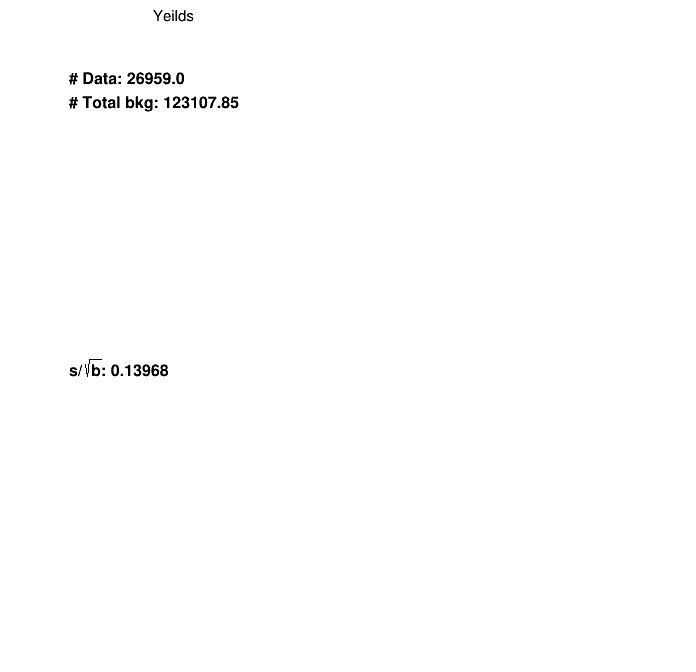

In [24]:
if DRAW_SR:
    region = "SR"

    with Pool() as p:
        p.starmap(wrapper_mp, list_variables) 
#     wrapper_mp('mass_pre', [45, 100, 1000, 'M_{ll} [GeV]'])

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)

In [25]:
# ###### wotop ######
# dic_variable={
#     "PuppiMET_pre": [14, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
#     "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
#     "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"], 
# }
# os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region+"/wotop")

# for variable, r in dic_variable.items():
#     if not "Puppi" in variable:
#         threshold = 0.3
#     else:
#         threshold = 0.5
#     hist=HistStack(dic_df_raw, variable, "weight", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/normblind_"+query_str, blind_from=threshold)        
#     hist=HistStack(dic_df_raw, variable, "weighthdampUp", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/normblind_hdampUp"+query_str, blind_from=threshold)
#     hist=HistStack(dic_df_raw, variable, "weighthdampDown", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/normblind_hdampDown"+query_str, blind_from=threshold)
#     hist=HistStack(dic_df_raw, variable, "weightPSUp", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/normblind_UEUp"+query_str, blind_from=threshold)
#     hist=HistStack(dic_df_raw, variable, "weightPSDown", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/normblind_UEDown"+query_str, blind_from=threshold)
#     hist=HistStack(dic_df_raw, variable, "wotop", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/wotop/norm_"+query_str, blind_from=threshold) 
# hist.get_yeilds()
# hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/wotop/pie_"+query_str)  

In [26]:
###### wobsf ######
dic_variable={
    "nbjetflav_pre": [10, 0, 10, "N bjetflav"],     
    "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
}
os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region+"/wobsf")

for variable, r in dic_variable.items():
    if not "Puppi" in variable:
        threshold = 0.3
    else:
        threshold = 0.5
    hist=HistStack(dic_df_raw, variable, "weight", r[0], r[1], r[2], r[3])  
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/normblind_"+query_str, blind_from=threshold)        
    hist=HistStack(dic_df_raw, variable, "wobsf", r[0], r[1], r[2], r[3])  
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/wobsf/norm_"+query_str, blind_from=threshold) 

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230523deepCSV_18/Presel/em18/SR/normblind_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_nbjetflav_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230523deepCSV_18/Presel/em18/SR/normblind_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_nbjetflav_pre.pdf has been created
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230523deepCSV_18/Presel/em18/SR/wobsf/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_nbjetflav_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230523deepCSV_18/Presel/em18/SR/wobsf/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_nbjetflav_pre.pdf has been created
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Prin

# Signal Acc x Eff x presel

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230523deepCSV_18/Presel/em18/SR/sig_eff.pdf has been created


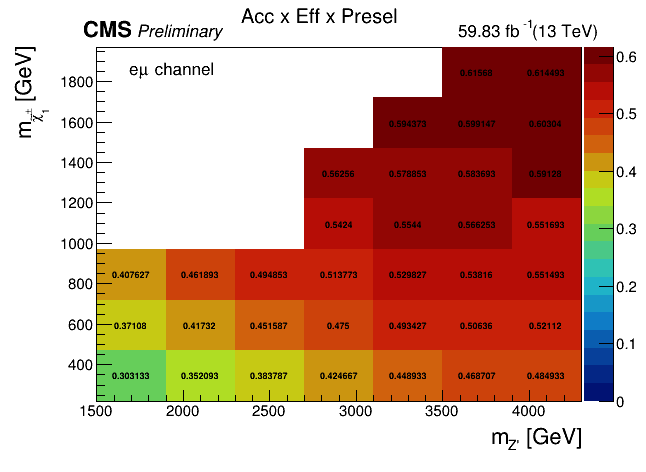

In [27]:
str_channel, str_lumi = HistStack.get_str_lumi_channel(ERA, ERA)

Zp_mass=[1700, 2100, 2500, 2900, 3300, 3700, 4100]
CH_mass=[345, 595, 845, 1095, 1345, 1595, 1845]
c1=rt.TCanvas("c1", "c1", 650, 500)
c1.SetLeftMargin(0.15)
c1.SetBottomMargin(0.15)
h2d1=rt.TH2D("h2d1", "", len(Zp_mass), Zp_mass[0]-200, Zp_mass[-1]+200, len(CH_mass), CH_mass[0]-125, CH_mass[-1]+125)
h2d1.SetTitle("Acc x Eff x Presel")

n_sig_in = 150000/4
if "em" in ERA:
    n_sig_in = 150000/2

for key in dic_df_raw:
    if not "Zp" in key:
        continue
    tmp=key.replace('_', '-')
    tmp=tmp.split('-')
    
    MZp=tmp[1]
    MCH=tmp[3]
    binx=Zp_mass.index(int(MZp))+1
    biny=CH_mass.index(int(MCH))+1
    h2d1.SetBinContent(binx, biny, dic_df_raw[key].shape[0]/(n_sig_in))
# # missing bin by hand
# h2d1.SetBinContent(5, 3, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000
# h2d1.SetBinContent(3, 4, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000

# set_palette("rainbow",255)
rt.gStyle.SetOptStat(0)
rt.gStyle.SetPalette(55)

h2d1.Draw("colz text")
h2d1.SetYTitle("m_{#tilde#chi_{1}^{#pm}} [GeV]")
h2d1.SetXTitle("m_{Z'} [GeV]")
h2d1.GetYaxis().SetTitleSize(0.05)
h2d1.GetXaxis().SetTitleSize(0.05)
latex=rt.TLatex()
latex.DrawLatexNDC( 0.2,0.84, "#scale[0.8]{#font[42]{"+str_channel+" channel}}")

latex1=rt.TLatex()
latex1.DrawLatexNDC(0.71, 0.92, "#font[42]{#scale[0.8]{"+str_lumi+" fb^{-1}(13 TeV)}}");
latex1.DrawLatexNDC(0.13, 0.92, "#font[62]{CMS}#font[42]{#it{#scale[0.8]{ Preliminary}}}");
 
c1.Draw()
c1.SaveAs(DATE+"/Presel/"+ERA+"/"+region+"/sig_eff.pdf")

# MET side band

In [28]:
if RUN_SIDEBAND_MET:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp    
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    dic_variable={
        "PuppiMET_pre": [20, 0, 100, "Puppi p_{T}^{miss} [GeV]"],    
#         "MET_pre": [40, 0, 400, "p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
#         "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
    #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
    #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
    #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],      
    }
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "METSB"
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)        

In [29]:
if DUMP_SIDEBAND_MET_PKL:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_METSB.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# Mass side band

In [30]:
if RUN_SIDEBAND_MASS and not "em" in ERA:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    
    dic_variable={
        "PuppiMET_pre": [28, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
        "mass_pre": [1,80, 100, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
    }

    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "MASSSB"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "mass_pre", "weight", 1, 80,  100, "M_{ll} [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.get_yeilds()
    hist.create_root_file(file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB") 
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)
    
    sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF"] 
#     sys_list = ["puweight", "l1prefiring", "effSF", "topSF"] 
    for s in sys_list:
        hist=HistStack(dic_df_raw, "mass_pre", 'weight'+s+'Up', 1, 80,  100, "M_{ll} [GeV]")
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
        hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
        hist=HistStack(dic_df_raw, "mass_pre", 'weight'+s+'Down', 1, 80,  100, "M_{ll} [GeV]")
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
        hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
    hist=HistStack(dic_df_met_u_tmp, "mass_pre", 'weightmetUp', 1, 80,  100, "M_{ll} [GeV]")
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB") 
    hist=HistStack(dic_df_met_d_tmp, "mass_pre", 'weightmetDown', 1, 80,  100, "M_{ll} [GeV]")
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")      

In [31]:
if DUMP_SIDEBAND_MASS_PKL and not "em" in ERA:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_MASS.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# PT side band

In [32]:
if RUN_SIDEBAND_PT:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre<40 and PuppiMET_pre>100"
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp    
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    dic_variable={
        "PuppiMET_pre": [14, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
#         "MET_pre": [40, 0, 400, "p_{T}^{miss} [GeV]"],    
        "mass_pre": [22, 100, 1000, "M_{ll} [GeV]"],
        "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [4, 0, 40, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [25, 0, 500, "p_{T}(ll) [GeV]"],
#         "MT_pre": [27, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [17, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [14, 0, 660, "U [GeV]"],
#         "JZB_pre": [14, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
#     #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
#     #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
#     #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#         "eta_lead_pre": [15, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [15, -3, 3, "#eta(l_{trail})"],
# #         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
# #         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [20, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],      
    }
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "PTSB"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "hdamp", "PS"]
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)        

In [33]:
if DUMP_SIDEBAND_PT_PKL:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_PT.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# b tag selection

In [ ]:
if RUN_BTAG:
    dic_variable={
#         "MET_pre": [25, 0, 500, "p_{T}^{miss} [GeV]"],    
#         "PuppiMET_pre": [50, 0, 500, "Puppi p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
#         "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"], 
        "nbjetflav_pre": [10, 0, 10, "N bjetflav"], 
#         "nbjet_pre": [10, 0, 10, "N bjet"], 
        "njet_pre": [10, 0, 10, "N jet"], 
#         "njet_l_pre": [9, 1, 10, "N  l jet"],     
#         "njet_c_pre": [9, 1, 10, "N  c jet"],     
#         "njet_b_pre": [9, 1, 10, "N  b jet"],    
#         "btagSF0_pre": [40, 0.9, 1.3, "B SF"],    
    }
    
#     base_line = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>80 and PuppiMET_pre>150 and MT_pre>130"
    base_line = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100 and njet_pre==1" #temp!
    query_str=base_line+" and nbjetflav_pre==0" #temp!
#     query_str=base_line #temp!

    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_met_ue_u_tmp = {}
    dic_df_met_ue_d_tmp = {}    
    
    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)
        dic_df_met_ue_u_tmp[key]=dic_df_met_ue_u[key].query(query_str) # probably pt cut incorrect
        dic_df_met_ue_d_tmp[key]=dic_df_met_ue_d[key].query(query_str)        
        print(key, ":", dic_df_raw[key].shape[0])

    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp
    nested_dic_df["met_ue_u"]=dic_df_met_ue_u_tmp
    nested_dic_df["met_ue_d"]=dic_df_met_ue_d_tmp
        
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "SR1"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "met", "metue", "trigSF", "hdamp", "PS", "btagSF"]
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str) 

    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_SR1.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)     
    
    ###############
    query_str=base_line+" and nbjetflav_pre>0" #temp!
#     query_str=base_line #temp!

    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_met_ue_u_tmp = {}
    dic_df_met_ue_d_tmp = {}    
    
    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)
        dic_df_met_ue_u_tmp[key]=dic_df_met_ue_u[key].query(query_str) # probably pt cut incorrect
        dic_df_met_ue_d_tmp[key]=dic_df_met_ue_d[key].query(query_str)        
        print(key, ":", dic_df_raw[key].shape[0])

    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp
    nested_dic_df["met_ue_u"]=dic_df_met_ue_u_tmp
    nested_dic_df["met_ue_d"]=dic_df_met_ue_d_tmp
        
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "TTCR"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "met", "metue", "trigSF", "hdamp", "PS", "btagSF"]
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)  
    
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_TTCR.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)    

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY : 29
TTDown : 64770
TTSemi : 280
TTUp : 62004
TTZ : 7789
TT : 147248
TThdampDown : 64662
TThdampUp : 59425
WW : 18172
WZ : 4923
ZZ : 158
Zp-1700_CH-345 : 22057
Zp-1700_CH-595 : 27026
Zp-1700_CH-845 : 29726
Zp-2100_CH-345 : 25608
Zp-2100_CH-595 : 30388
Zp-2100_CH-845 : 33686
Zp-2500_CH-345 : 27790
Zp-2500_CH-595 : 32857
Zp-2500_CH-845 : 35959
Zp-2900_CH-1095 : 39445
Zp-2900_CH-1345 : 40776
Zp-2900_CH-345 : 30802
Zp-2900_CH-595 : 34412
Zp-2900_CH-845 : 37311
Zp-3300_CH-1095 : 40207
Zp-3300_CH-1345 : 41977
Zp-3300_CH-1595 : 42904
Zp-3300_CH-345 : 32503
Zp-3300_CH-595 : 35765
Zp-3300_CH-845 : 38413
Zp-3700_CH-1095 : 41026
Zp-3700_CH-1345 : 42321
Zp-3700_CH-1595 : 43368
Zp-3700_CH-1845 : 44343
Zp-3700_CH-345 : 33879
Zp-3700_CH-595 : 36644
Zp-3700_CH-845 : 38973
Zp-4100_CH-1095 : 39832
Zp-4100_CH-1345 : 42887
Zp-4100_CH-1595 : 43617

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/tmp/ipykernel_725/1903289986.py", line 69, in <module>
    p.starmap(wrapper_mp, list_variables)
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/pool.py", line 372, in starmap
    return self._map_async(func, iterable, starmapstar, chunksize).get()
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/pool.py", line 765, in get
    self.wait(timeout)
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/pool.py", line 762, in wait
    self._event.wait(timeout)
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/threading.py", line 574, in wait
    signaled = self._cond.wait(timeout)
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/threading.py", line 312, in wai

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/tmp/ipykernel_725/1903289986.py", line 69, in <module>
    p.starmap(wrapper_mp, list_variables)
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/pool.py", line 372, in starmap
    return self._map_async(func, iterable, starmapstar, chunksize).get()
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/pool.py", line 765, in get
    self.wait(timeout)
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/pool.py", line 762, in wait
    self._event.wait(timeout)
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/threading.py", line 574, in wait
    signaled = self._cond.wait(timeout)
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/threading.py", line 312, in wai

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230523deepCSV_18/Presel/em18/SR1/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100 and nbjetflav_pre==0_nbjetflav_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230523deepCSV_18/Presel/em18/SR1/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100 and nbjetflav_pre==0_nbjetflav_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230523deepCSV_18/Presel/em18/SR1/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100 and nbjetflav_pre==0_pt_trail_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230523deepCSV_18/Presel/em18/SR1/sys/norm_

# Export variables

In [34]:
if EXPORT_VARIABLE:
    # draw
    # get plot configuration
    dic_variable={
    #     "pt_trail_pre": [8, 40, 300, "p_{T}(l_{trail}) [GeV]"],
    #     "MT2_pre": [8, 0, 160, "M_{T2} [GeV]"],
        "H3PP_pre": [19, 95, 900, "H3PP [GeV]"],     
    }
    sys_src={
        "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre"]
    #     "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre", "topSF_pre"]
    }
    # sys_src=[]
    for key in dic_df_raw:
        if "Zp" in key:
            for variable, r in dic_variable.items():
                hist=HistStack(dic_df_raw, variable, sys_src, "presel", r[0], r[1], r[2], r[3])            
                c1=hist.draw_hist(key, ERA, ERA+"_exportdev"+query_str, True) 
                hist.create_root_file(key, variable, channel)
                hist.export_hist(key, variable, channel, "") 

    #simply from last instance
    print(hist.get_yeilds())
    hist.draw_pie()
    print(hist.nbin)


ERROR! Session/line number was not unique in database. History logging moved to new session 4
Error in callback <bound method StreamCapture.post_execute of <JupyROOT.helpers.utils.StreamCapture object at 0x7f528ded94c0>> (for post_execute):


KeyboardInterrupt: 